## SST

In [46]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [47]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

import sys
from pathlib import Path
import os

from scipy.io import loadmat
from helper import plot_training_curves, evaluate_model, plot_reconstruction, plot_sst_with_buoys, plot_sst_overview_and_availability

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))
DATA_DIR = Path.cwd() / "datasets"  

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Exploration

In [ ]:
# Load SST data -> X RAW
X_raw = np.load(DATA_DIR / "sst_all_ROM.npy")
print(f"Loaded SST data with shape: {X_raw.shape}")
S_raw = np.load(DATA_DIR / "buoy_all_ROM.npy")
print(f"Loaded Buoy data with shape: {S_raw.shape}\n")

loc = pd.read_csv(DATA_DIR / "stations_location.csv", dtype={"station": str})
S_names = loc["station"].to_numpy()
S_lat = loc["lat"].to_numpy()
S_lon = loc["lon"].to_numpy()

for i, name in enumerate(S_names):
    print(f"Buoy {name} at lat: {S_lat[i]}, lon: {S_lon[i]}")

np.random.seed(42)
permutation = np.random.permutation(X_raw.shape[0])
X_raw = X_raw[permutation]
S_raw = S_raw[permutation]

X_raw = X_raw.reshape(-1, 180 * 360)
S_raw = S_raw.reshape(-1, 20)

print(f"\nReshaped X_raw to: {X_raw.shape}")
print(f"Reshaped S_raw to: {S_raw.shape}")

Loaded SST data with shape: (26, 365, 64800)
Loaded Buoy data with shape: (26, 365, 20)

Buoy 46035 at lat: 57.034, lon: -177.468
Buoy 46001 at lat: 56.296, lon: -148.027
Buoy 46066 at lat: 52.776, lon: -154.992
Buoy 46006 at lat: 40.73, lon: -137.42
Buoy 46059 at lat: 38.067, lon: -129.895
Buoy 46025 at lat: 33.765, lon: -119.077
Buoy 51001 at lat: 24.475, lon: -162.03
Buoy 51004 at lat: 17.504, lon: -152.197
Buoy 52200 at lat: 13.354, lon: 144.788
Buoy 44013 at lat: 42.346, lon: -70.651
Buoy 41001 at lat: 34.738, lon: -72.503
Buoy 41010 at lat: 28.86, lon: -78.478
Buoy 41046 at lat: 23.84, lon: -68.34
Buoy 41043 at lat: 21.09, lon: -64.864
Buoy 41044 at lat: 21.582, lon: -58.63
Buoy 42057 at lat: 16.975, lon: -81.578
Buoy 42058 at lat: 14.114, lon: -75.949
Buoy 42040 at lat: 29.207, lon: -88.237
Buoy 42001 at lat: 25.922, lon: -89.638
Buoy 42002 at lat: 25.95, lon: -93.78

Reshaped X_raw to: (18980, 64800)
Reshaped S_raw to: (18980, 20)


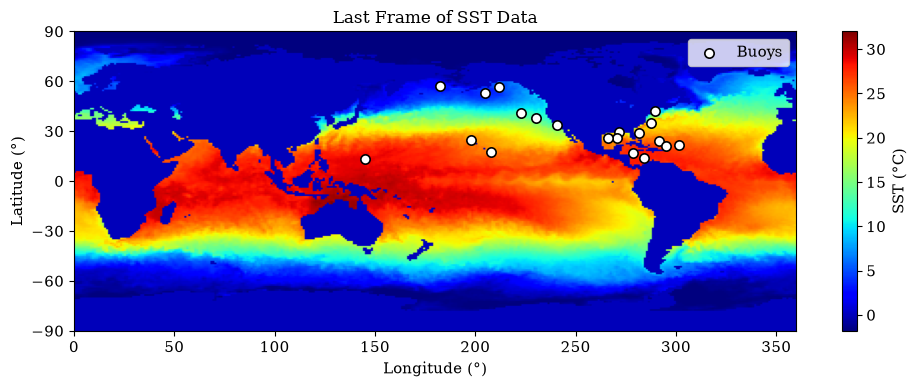

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Load SST data -> X CLEAN
mean_X = np.mean(X_raw, axis=0)
sst_locs = np.where(mean_X != 0)[0]

X_clean = X_raw[:, sst_locs]
S_clean = S_raw

# Plot dell'ultimo frame
fig, ax = plot_sst_with_buoys(X_raw, S_lon, S_lat)

In [50]:
print(X_clean.shape, S_clean.shape)

(18980, 41027) (18980, 20)


In [51]:
ERRORS = []

# DataManager
LAGS = 40

TRAIN_SIZE = 0.70        # percentage of data used for training 
VAL_SIZE = 0.15          # percentage of data used for validation
TEST_SIZE = 0.15         # percentage of data used for testing

COMPRESS_SST = 500

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [256]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## Training

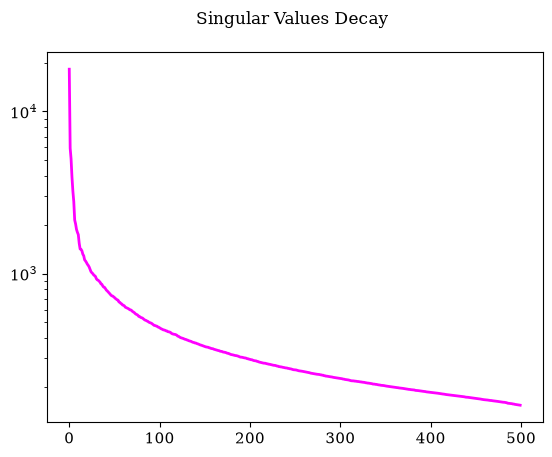

Residual energy of Surface elevation after keeping 500 modes: 2.8549 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 102758

Data shapes after preparation:
Train:	 torch.Size([13286, 40, 20]) -> torch.Size([13286, 500])
Val:	 torch.Size([2847, 40, 20]) -> torch.Size([2847, 500])
Test:	 torch.Size([2847, 40, 20]) -> torch.Size([2847, 500])

Input shape for the model: 20
Output shape for the model: 500


In [52]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(X_clean, id="Surface elevation", compress=COMPRESS_SST, measurements=S_clean, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training: 100%|██████████| 200/200 [27:35<00:00,  8.28s/it, Train Loss=0.00925, Val Loss=0.01185, Patience=36, Best Val Loss=0.01184, LR=0.00e+00]

Training completed with best validation loss: 0.0118


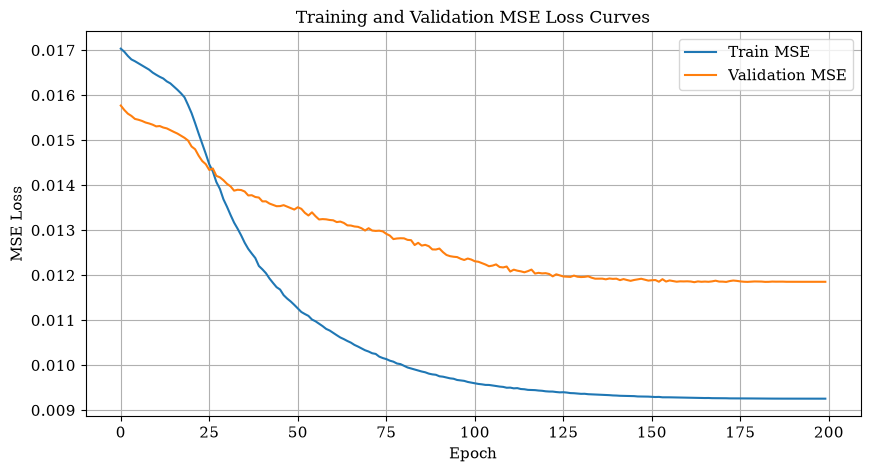

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.009272,0.011842,0.01088,0.195687,0.22068,0.210448,0.099945,0.113579,0.108379


In [53]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [56]:
#save the model
if not os.path.exists("models"):
    os.makedirs("models")
if not os.path.exists("models/mSHRED_model.pth"):
    torch.save(mshred.state_dict(), "models/mSHRED_model.pth")
else:
    print("Model already exists. Skipping save.")

model = torch.load("models/mSHRED_model.pth", map_location=device)  

Model already exists. Skipping save.


In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

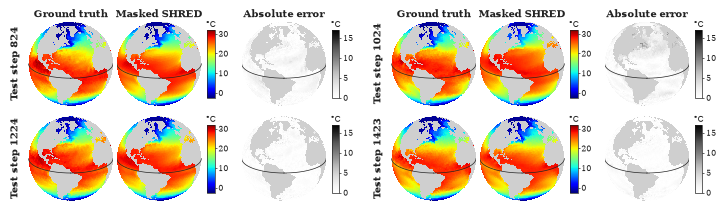

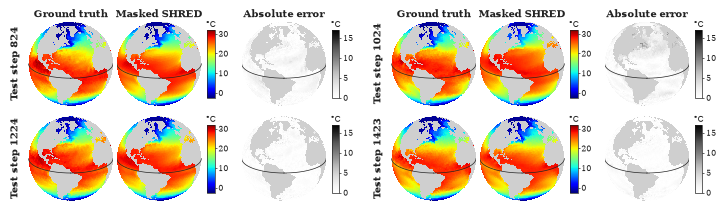

In [63]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, to_rgba

PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.linewidth": 0.9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}
C_TEXT = "#222222"
# se nel notebook hai già C_LAND (quello usato nella figura delle boe) viene riusato, altrimenti grigio chiaro
C_LAND = globals().get("C_LAND", "#cfcfcf")


# --------------------------------------------------------------------------------------
# Globo 2D in proiezione ortografica (stesso tipo di rappresentazione della figura delle boe)
# --------------------------------------------------------------------------------------
def _globe_lookup(shape, view_lon, view_lat, res=700):
    """Per ogni pixel del disco: riga/colonna della griglia (lat,lon) da campionare."""
    n_lat, n_lon = shape
    g = np.linspace(-1, 1, res)
    x, y = np.meshgrid(g, g)                 # con origin='lower' y cresce verso l'alto
    r2 = x ** 2 + y ** 2
    inside = r2 <= 1.0
    z = np.sqrt(np.clip(1 - r2, 0, None))
    p0, l0 = np.deg2rad(view_lat), np.deg2rad(view_lon)
    lat = np.rad2deg(np.arcsin(np.clip(z * np.sin(p0) + y * np.cos(p0), -1, 1)))
    lon = (np.rad2deg(l0 + np.arctan2(x, z * np.cos(p0) - y * np.sin(p0)))) % 360
    rows = np.clip(np.floor((90 - lat) * n_lat / 180).astype(int), 0, n_lat - 1)   # riga 0 = lat 90
    cols = np.floor(lon * n_lon / 360).astype(int) % n_lon                          # colonna 0 = lon 0
    return rows, cols, inside


def _draw_globe(ax, field, bad, lookup, cmap, norm, land_rgba, view_lon, view_lat, show_equator=True):
    rows, cols, inside = lookup
    vals = np.where(bad, norm.vmin, np.nan_to_num(field, nan=norm.vmin))[rows, cols]
    rgba = cmap(norm(vals))
    rgba[bad[rows, cols]] = land_rgba
    rgba[~inside, 3] = 0.0
    ax.imshow(rgba, origin='lower', extent=(-1, 1, -1, 1), interpolation='nearest', zorder=1)

    if show_equator:
        p0 = np.deg2rad(view_lat)
        d = np.linspace(0, 2 * np.pi, 721)
        ex, ey, ez = np.sin(d), -np.sin(p0) * np.cos(d), np.cos(p0) * np.cos(d)
        vis = ez > 0
        ax.plot(np.where(vis, ex, np.nan), np.where(vis, ey, np.nan),
                color=C_TEXT, lw=0.5, zorder=3)

    ax.set_xlim(-1.005, 1.005)
    ax.set_ylim(-1.005, 1.005)
    ax.set_aspect('equal')
    ax.axis('off')


def plot_reconstruction_globes(
    test_reconstruction, X_raw, sst_locs,
    indices=(-600, -400, -200, -1),
    variable='Surface elevation',   # chiave in test_reconstruction
    shape=(180, 360),
    label_offset=None,              # es. 1424 -> etichetta = 1424 + idx; None -> indice reale
    cmap='jet',                     # stessa cmap della figura delle boe
    err_cmap='Greys',
    land_color=None,                # None -> C_LAND
    missing_value=0.0,              # valore = terra/mancante (oltre a NaN); None per ignorarlo
    shared_scale=True,              # True: stessa scala colori per tutti e 4 i timestep
    vlim=None,                      # (vmin, vmax) manuali per GT/SHRED, es. (0, 30); None -> min/max sui 4 timestep
    err_max=None,                   # massimo manuale per l'errore; None -> massimo sui 4 timestep
    cbar_label='°C',
    view_lon=310.0, view_lat=20.0,  # centro del globo (310°E = 50°W: costa est delle Americhe + Atlantico)
    show_equator=True,
    width=7.2,                      # larghezza figura in pollici (doppia colonna ~7.0-7.2; il resto si adatta da solo)
    font_title=7.0, font_label=7.0, font_tick=6.0,   # pt: nessun testo sotto i 6 pt
    title=None,                     # opzionale; per il paper meglio None (caption LaTeX)
    save_path=None,                 # senza estensione, es. 'outputs/mSHRED_globes'
    formats=('pdf', 'png'),
    dpi=600,
):
    """
    Griglia 2x2: ogni cella = [Ground truth | Masked SHRED | cbar | Absolute error | cbar]
    su globi ortografici 2D. Il layout è calcolato in pollici (nessuna sovrapposizione di testo):
    il diametro dei globi si ricava dalla larghezza della figura.
    """
    assert len(indices) == 4, "servono esattamente 4 timestep"
    cmap = plt.get_cmap(cmap)
    err_cmap = plt.get_cmap(err_cmap)
    land_rgba = to_rgba(C_LAND if land_color is None else land_color)
    lookup = _globe_lookup(shape, view_lon, view_lat)

    # ---------------- geometria (pollici) ----------------
    lab_w, lab_gap = 0.17, 0.05          # colonna etichetta "Test step N"
    g_gap = 0.035                        # tra Ground truth e Masked SHRED
    cb_gap, cb_w, cb_room = 0.055, 0.075, 0.24   # distanza globo→cbar, larghezza cbar, spazio per i tick
    e_gap = 0.03                         # tra cbar GT/SHRED e globo errore (oltre a cb_room)
    block_gap = 0.06
    fixed = lab_w + lab_gap + g_gap + 2 * (cb_gap + cb_w + cb_room) + e_gap
    d = (width - 2 * fixed - block_gap) / 6.0          # diametro del globo
    block_w = fixed + 3 * d

    title_h = 0.20                       # spazio per i titoli colonna
    sup_h = 0.22 if title else 0.0
    row_gap = 0.10
    bottom = 0.02
    height = bottom + 2 * d + row_gap + title_h + sup_h

    def fx(x):  # pollici -> frazione figura
        return x / width

    def fy(y):
        return y / height

    # ---------------- dati e scale ----------------
    fields = []
    for idx in indices:
        hat = np.zeros(X_raw.shape[1])
        hat[sst_locs] = test_reconstruction[variable][idx]
        orig = np.asarray(X_raw[idx], float).reshape(shape)
        hat = hat.reshape(shape)
        bad = np.isnan(orig)
        if missing_value is not None:
            bad |= orig == missing_value
        fields.append((orig, hat, np.abs(orig - hat), bad))

    if shared_scale:   # stessa scala per tutti e 4 i timestep (GT e SHRED insieme; errore a parte)
        if vlim is None:
            vmin = min(min(o[~b].min(), h[~b].min()) for o, h, e, b in fields)
            vmax = max(max(o[~b].max(), h[~b].max()) for o, h, e, b in fields)
        else:
            vmin, vmax = vlim
        emax = max(e[~b].max() for o, h, e, b in fields) if err_max is None else err_max
        norm_shared = Normalize(vmin=vmin, vmax=vmax)
        norm_err_shared = Normalize(vmin=0, vmax=emax)

    with plt.rc_context({**PAPER_RC, 'font.size': font_tick, 'text.color': C_TEXT}):
        fig = plt.figure(figsize=(width, height))

        for k, idx in enumerate(indices):
            r, c = k // 2, k % 2
            x0 = c * (block_w + block_gap)
            y0 = bottom + (1 - r) * (d + row_gap)       # riga 0 in alto

            orig, hat, err, bad = fields[k]
            if shared_scale:
                norm, norm_err = norm_shared, norm_err_shared
            else:
                vmin = min(orig[~bad].min(), hat[~bad].min())
                vmax = max(orig[~bad].max(), hat[~bad].max())
                norm = Normalize(vmin=vmin, vmax=vmax) if vlim is None else Normalize(*vlim)
                norm_err = Normalize(vmin=0, vmax=err[~bad].max() if err_max is None else err_max)

            # --- posizioni x dei pannelli ---
            xg1 = x0 + lab_w + lab_gap
            xg2 = xg1 + d + g_gap
            xcb1 = xg2 + d + cb_gap
            xg3 = xcb1 + cb_w + cb_room + e_gap
            xcb2 = xg3 + d + cb_gap

            axes = [fig.add_axes([fx(xx), fy(y0), fx(d), fy(d)]) for xx in (xg1, xg2, xg3)]
            for ax, f, cm, nm in zip(axes, (orig, hat, err), (cmap, cmap, err_cmap), (norm, norm, norm_err)):
                _draw_globe(ax, f, bad, lookup, cm, nm, land_rgba, view_lon, view_lat, show_equator)

            # colorbar verticali (80% dell'altezza del globo, centrate)
            cb_h = 0.8 * d
            for xcb, cm, nm in ((xcb1, cmap, norm), (xcb2, err_cmap, norm_err)):
                cax = fig.add_axes([fx(xcb), fy(y0 + 0.1 * d), fx(cb_w), fy(cb_h)])
                cb = fig.colorbar(ScalarMappable(norm=nm, cmap=cm), cax=cax)
                cb.ax.tick_params(labelsize=font_tick, length=1.5, width=0.5, pad=1.2,
                                  labelcolor=C_TEXT, color=C_TEXT)
                cb.outline.set_linewidth(0.5)
                cb.outline.set_edgecolor(C_TEXT)
                if cbar_label:
                    cb.ax.set_title(cbar_label, fontsize=font_tick, color=C_TEXT, pad=2)

            # titoli colonna solo sulla riga superiore
            if r == 0:
                for ax, t in zip(axes, ('Ground truth', 'Masked SHRED', 'Absolute error')):
                    ax.set_title(t, fontsize=font_title, fontweight='bold', pad=3, color=C_TEXT)

            # etichetta verticale "Test step N" (sta dentro l'altezza del globo)
            step = (label_offset + idx) if label_offset is not None else idx % len(X_raw)
            fig.text(fx(x0 + lab_w / 2), fy(y0 + d / 2), f'Test step {step}',
                     rotation=90, ha='center', va='center', fontsize=font_label,
                     fontweight='bold', color=C_TEXT)

        if title:
            fig.suptitle(title, fontsize=font_title + 2, fontweight='bold', y=0.995, color=C_TEXT)

        if save_path:
            os.makedirs(os.path.dirname(save_path) or '.', exist_ok=True)
            for ext in formats:
                fig.savefig(f'{save_path}.{ext}', dpi=dpi, bbox_inches='tight', pad_inches=0.02)
        plt.show()
    return fig


# --- uso ---
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
plot_reconstruction_globes(
    test_reconstruction, X_raw, sst_locs,
    indices=(-600, -400, -200, -1),
    label_offset=1424,
    title=None, 
    save_path='SST_2_grid_recconstruction',   # salva .pdf e .png a 600 dpi
)